# 쓰레기 사진 12종 분류 — 학습된 모델로 예측하기

**사용 방법**
1. 바로 아래 셀의 `TEST_DIR`에 사진 폴더 경로를 넣음
2. 모든 셀 실행 (Colab: 런타임 → 모두 실행) → 학습 없이 저장된 모델로 바로 예측함

**사진 폴더는 두 형태 모두 됨**
- 사진만 넣은 폴더 → 사진별 예측 결과
- 클래스 이름으로 된 하위 폴더(`battery/`, `metal/` …)에 나눠 넣은 폴더 → 예측 + 정확도·혼동행렬까지 계산

클래스 12종: battery, biological, brown-glass, cardboard, clothes, green-glass, metal, paper, plastic, shoes, trash, white-glass

모델: 직접 설계한 CNN 2개의 앙상블 (사전학습 가중치 사용 안 함)
- 두 모델의 확률을 평균함 (좌우로 뒤집은 사진의 확률도 같이 평균)
- 입력 크기 160px, 학습 데이터의 클래스 비율로 확률을 보정함
- test 정확도 0.956, 평가 사이트(AI 생성 사진 60장) 73.33% → 자세한 내용은 `README.md`

In [1]:
TEST_DIR = 'sample_images'      # ← 사진 폴더 경로로 바꿈 (예: '/content/test_photos')

# 학습된 모델 파일 2개 (모델 1개당 파일 1개, 없으면 아래 주소에서 자동으로 내려받음)
MODEL_FILES = ['final_model_1.pt', 'final_model_2.pt']
MODEL_URL = 'https://github.com/jeongwoo0611/JW/raw/main/'

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from sklearn.metrics import classification_report

device = 'cuda' if torch.cuda.is_available() else 'cpu'     # GPU가 없으면 CPU로 계산함 (결과는 같음)
print('device:', device, '| torch', torch.__version__)

device: cuda | torch 2.14.1+cu130


## 1. 모델 구조 (학습 때와 같음)

In [3]:
# residual 블록: 3x3 합성곱 2개를 거친 값 + 입력을 그대로 더함 (크기가 바뀌는 블록은 1x1 합성곱으로 입력 크기를 맞춤)
class Block(nn.Module) :
    def __init__(self, c_in, c_out, stride) :
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(c_in, c_out, 3, stride, 1, bias = False), nn.BatchNorm2d(c_out), nn.ReLU(inplace = True),
            nn.Conv2d(c_out, c_out, 3, 1, 1, bias = False), nn.BatchNorm2d(c_out))
        if stride == 1 and c_in == c_out :
            self.skip = nn.Identity()
        else :
            self.skip = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias = False), nn.BatchNorm2d(c_out))

    def forward(self, x) :
        return F.relu(self.body(x) + self.skip(x))


# CNN3: 첫 합성곱(크기 1/2) → residual 블록 2개씩 4단계(채널 64/128/256/512) → 전역 평균 풀링 → Dropout → 12개 클래스 점수
class CNN3(nn.Module) :
    def __init__(self, widths = (64, 128, 256, 512), dropout = 0.2, n_classes = 12) :
        super().__init__()
        layers = [nn.Conv2d(3, widths[0], 3, 2, 1, bias = False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace = True)]
        c = widths[0]
        for i, w in enumerate(widths) :
            layers += [Block(c, w, 1 if i == 0 else 2), Block(w, w, 1)]
            c = w
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(c, n_classes))

    def forward(self, x) :
        return self.head(self.features(x))

## 2. 학습된 모델 2개 불러오기

In [4]:
# 모델 파일이 없으면 GitHub에서 내려받음 (파일 1개당 약 22MB)
for f in MODEL_FILES :
    if not os.path.exists(f) :
        print('모델 파일을 내려받는 중 ←', MODEL_URL + f)
        torch.hub.download_url_to_file(MODEL_URL + f, f)

# 모델 파일 = 가중치 + 예측에 필요한 값 (클래스 이름, 입력 정규화 평균·표준편차, 입력 크기, 학습 데이터의 클래스 비율)
models = []
for f in MODEL_FILES :
    saved = torch.load(f, map_location = device)
    m = CNN3(n_classes = len(saved['classes'])).to(device)
    m.load_state_dict(saved['states'][0])      # fp16으로 저장한 가중치가 fp32 모델에 들어감
    models.append(m.eval())
    print(f, '|', saved['model'])

# 예측에 필요한 값은 두 파일이 같음
CLASSES = saved['classes']
SIZE = saved['image_size']                      # 160px
MEAN = torch.tensor(saved['mean']).view(1, 3, 1, 1).to(device)
STD = torch.tensor(saved['std']).view(1, 3, 1, 1).to(device)
PRIOR = torch.tensor(saved['prior'])            # 학습 데이터의 클래스 비율 (clothes가 26%로 가장 많음)
print('입력 크기', SIZE, '| 클래스', CLASSES)
print('학습 데이터 클래스 비율', dict(zip(CLASSES, PRIOR.numpy().round(3))))

final_model_1.pt | CNN3 #1: dataset v3, basic augmentation, seed 12345 | size 160, flip average, prior fix (final model = #1 + #2 averaged)


final_model_2.pt | CNN3 #2: dataset v3, basic + colour augmentation (not on glass), seed 12345 | size 160, flip average, prior fix (final model = #1 + #2 averaged)
입력 크기 160 | 클래스 ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
학습 데이터 클래스 비율 {'battery': np.float32(0.049), 'biological': np.float32(0.077), 'brown-glass': np.float32(0.033), 'cardboard': np.float32(0.071), 'clothes': np.float32(0.259), 'green-glass': np.float32(0.036), 'metal': np.float32(0.092), 'paper': np.float32(0.086), 'plastic': np.float32(0.097), 'shoes': np.float32(0.099), 'trash': np.float32(0.036), 'white-glass': np.float32(0.065)}


## 3. 사진 불러오기

In [5]:
assert os.path.isdir(TEST_DIR), f'사진 폴더가 없음: {TEST_DIR} → 맨 위 TEST_DIR 경로를 확인해 주세요'

# 폴더 안의 사진 파일을 하위 폴더까지 모두 찾음
EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp', '.tif', '.tiff')
paths = sorted(os.path.join(root, f) for root, _, files in os.walk(TEST_DIR) for f in files if f.lower().endswith(EXT))
assert len(paths) > 0, f'{TEST_DIR} 안에 사진 파일({", ".join(EXT)})이 없음'

# 학습 때와 같은 전처리: RGB 3채널로 바꾸고, 비율과 관계없이 SIZE x SIZE 정사각형으로 맞춤
# + 휴대폰 사진의 회전 정보(EXIF)를 반영해서 사진을 바로 세움 (안 하면 누운 사진이 들어갈 수 있음)
images, files = [], []
for p in paths :
    try :
        img = ImageOps.exif_transpose(Image.open(p)).convert('RGB').resize((SIZE, SIZE), Image.BICUBIC)
    except Exception as e :
        print('읽을 수 없는 파일이라 건너뜀:', p, '|', e)
        continue
    images.append(torch.from_numpy(np.array(img)).permute(2, 0, 1))
    files.append(p)
x_all = torch.stack(images)

# 사진 바로 위 폴더 이름이 클래스 이름이면 정답으로 씀 (아니면 정답 없음)
labels = [os.path.basename(os.path.dirname(p)) for p in files]
labels = [lab if lab in CLASSES else None for lab in labels]
print('사진', len(files), '장 | 정답 폴더가 있는 사진', sum(lab is not None for lab in labels), '장')

사진 24 장 | 정답 폴더가 있는 사진 24 장


## 4. 예측

In [6]:
# 64장씩 나눠 클래스별 확률을 계산함
#  1) 모델 2개 x (원래 사진, 좌우로 뒤집은 사진) = 확률 4개를 평균함
#  2) 클래스 비율 보정: 평균 확률을 학습 데이터의 클래스 비율로 나누고 합이 1이 되게 다시 나눔
#     → 학습 데이터에 많은 클래스(clothes 26%) 쪽으로 쏠린 예측을 바로잡음 (평가 사진은 클래스마다 같은 수라고 봄)
prob = []
with torch.no_grad() :
    for i in range(0, len(x_all), 64) :
        x = (x_all[i:i + 64].to(device).float() / 255 - MEAN) / STD
        p = torch.stack([m(v).softmax(1) for m in models for v in (x, x.flip(3))]).mean(0).cpu()
        p = p / PRIOR
        prob.append(p / p.sum(1, keepdim = True))
prob = torch.cat(prob).numpy()

# 사진별 결과: 예측 클래스와 확률, 2순위 예측, 정답 폴더가 있으면 정답과 맞았는지
order = prob.argsort(1)
result = pd.DataFrame({'file': [os.path.relpath(p, TEST_DIR) for p in files],
                       'pred': np.array(CLASSES)[order[:, -1]], 'prob': prob.max(1).round(3),
                       '2nd': np.array(CLASSES)[order[:, -2]], '2nd prob': np.sort(prob, 1)[:, -2].round(3),
                       'label': labels})
result['correct'] = (result['pred'] == result['label']).where(result['label'].notna())
result.to_csv('predictions.csv', index = False, encoding = 'utf-8-sig')
print('저장함 → predictions.csv\n')
print(result['pred'].value_counts().to_string())
result

저장함 → predictions.csv

pred
battery        2
biological     2
brown-glass    2
cardboard      2
clothes        2
green-glass    2
metal          2
paper          2
plastic        2
shoes          2
trash          2
white-glass    2


,file,pred,prob,2nd,2nd prob,label,correct
0,battery\battery51.jpg,battery,0.869,trash,0.022,battery,True
1,battery\battery894.jpg,battery,0.924,trash,0.023,battery,True
2,biological\biological849.jpg,biological,0.798,metal,0.067,biological,True
3,biological\biological953.jpg,biological,0.880,brown-glass,0.017,biological,True
4,brown-glass\brown-glass111.jpg,brown-glass,0.937,green-glass,0.009,brown-glass,True
5,brown-glass\brown-glass383.jpg,brown-glass,0.927,green-glass,0.014,brown-glass,True
6,cardboard\cardboard107.jpg,cardboard,0.564,paper,0.239,cardboard,True
7,cardboard\cardboard855.jpg,cardboard,0.822,battery,0.029,cardboard,True
8,clothes\clothes2303.jpg,clothes,0.636,brown-glass,0.054,clothes,True
9,clothes\clothes426.jpg,clothes,0.635,brown-glass,0.052,clothes,True


## 5. 정확도 (정답 폴더가 있을 때만)

정확도: 1.0000 (24 / 24장)

              precision    recall  f1-score   support

     battery      1.000     1.000     1.000         2
  biological      1.000     1.000     1.000         2
 brown-glass      1.000     1.000     1.000         2
   cardboard      1.000     1.000     1.000         2
     clothes      1.000     1.000     1.000         2
 green-glass      1.000     1.000     1.000         2
       metal      1.000     1.000     1.000         2
       paper      1.000     1.000     1.000         2
     plastic      1.000     1.000     1.000         2
       shoes      1.000     1.000     1.000         2
       trash      1.000     1.000     1.000         2
 white-glass      1.000     1.000     1.000         2

    accuracy                          1.000        24
   macro avg      1.000     1.000     1.000        24
weighted avg      1.000     1.000     1.000        24



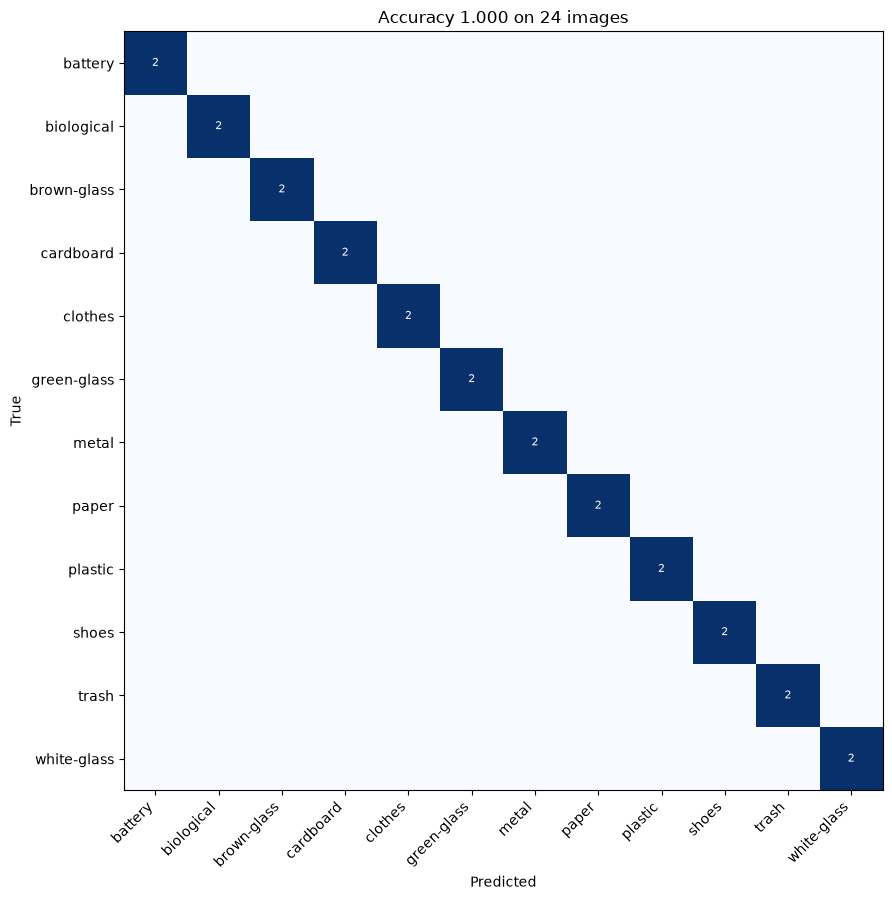

In [7]:
lab = result[result['label'].notna()]
if len(lab) == 0 :
    print('정답 폴더가 없어서 정확도는 계산하지 않음 → 사진별 예측은 위 표와 predictions.csv')
else :
    print(f"정확도: {(lab['pred'] == lab['label']).mean():.4f} ({(lab['pred'] == lab['label']).sum()} / {len(lab)}장)\n")
    used = [c for c in CLASSES if c in set(lab['label']) | set(lab['pred'])]
    print(classification_report(lab['label'], lab['pred'], labels = used, digits = 3, zero_division = 0))

    # 혼동행렬: 행 = 정답, 열 = 예측, 칸의 숫자 = 사진 수, 색 = 정답 기준 비율
    cm = pd.crosstab(lab['label'], lab['pred']).reindex(index = used, columns = used, fill_value = 0)
    rate = cm.values / np.maximum(cm.values.sum(1, keepdims = True), 1)
    fig, ax = plt.subplots(figsize = (0.6 * len(used) + 3, 0.55 * len(used) + 2.5))
    ax.imshow(rate, cmap = 'Blues', vmin = 0, vmax = 1)
    for i in range(len(used)) :
        for j in range(len(used)) :
            if cm.values[i, j] > 0 :
                ax.text(j, i, cm.values[i, j], ha = 'center', va = 'center', fontsize = 8, color = 'white' if rate[i, j] > 0.5 else 'black')
    ax.set_xticks(range(len(used)), used, rotation = 45, ha = 'right')
    ax.set_yticks(range(len(used)), used)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f"Accuracy {(lab['pred'] == lab['label']).mean():.3f} on {len(lab)} images")
    plt.tight_layout()
    plt.show()

## 6. 예측 결과 보기 (최대 24장)

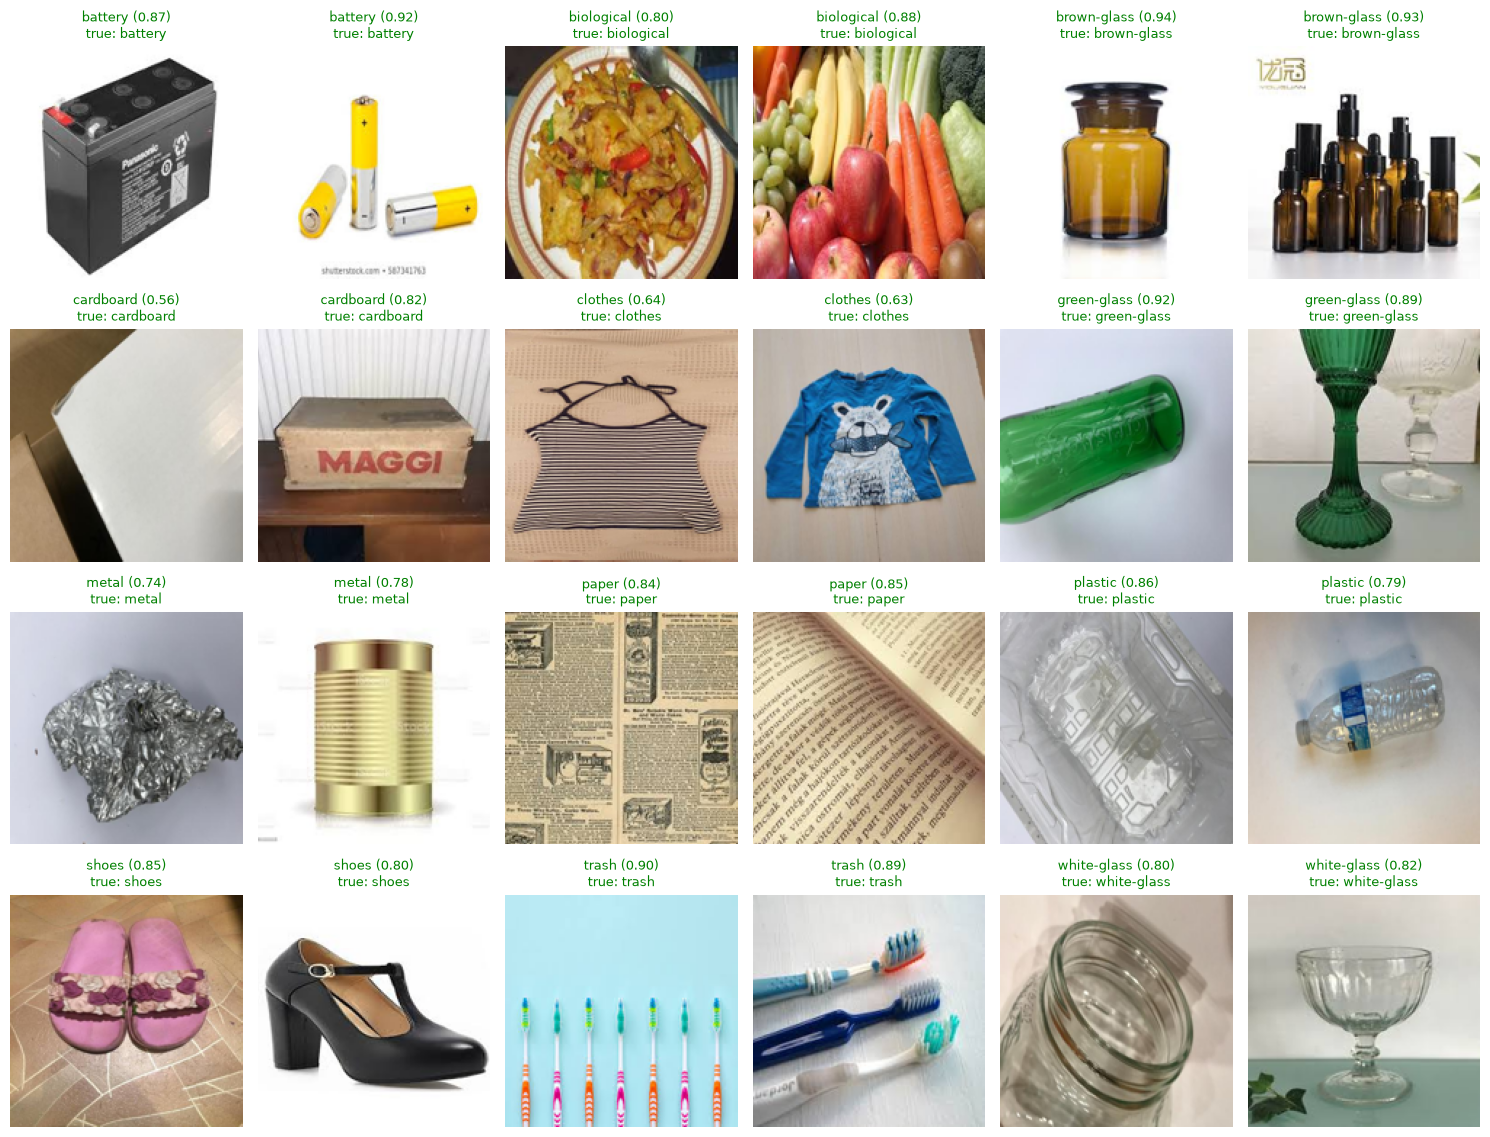

In [8]:
# 제목 = 예측 (확률) / 정답 폴더가 있으면 맞으면 초록, 틀리면 빨강
show = result.sample(min(24, len(result)), random_state = 0).sort_index()
fig, axes = plt.subplots((len(show) + 5) // 6, 6, figsize = (15, 2.9 * ((len(show) + 5) // 6)), squeeze = False)
for ax in axes.flat :
    ax.axis('off')
for ax, (i, r) in zip(axes.flat, show.iterrows()) :
    ax.imshow(x_all[i].permute(1, 2, 0).numpy())
    has_label = pd.notna(r['label'])
    title = f"{r['pred']} ({r['prob']:.2f})" + (f"\ntrue: {r['label']}" if has_label else '')
    color = ('green' if r['correct'] else 'red') if has_label else 'black'
    ax.set_title(title, fontsize = 9, color = color)
plt.tight_layout()
plt.show()